# Learning curves for the regularization candidates

Do the candidates in `regularization.ipynb` really reduce overfitting, and do they learn anything that holds on unseen days? Each curve shows loss at every step with early stopping off, on walk-forward rounds 1, 4 and 8, for all 4 input sets. Only each round's known days are used, so scored days and the test split stay untouched.

This uses **1 seed (42)**, so differences between single curves can be chance. The control is the same seed from `learning_curves.csv`.

Losses are divided by the baseline's loss on the same data, so **1 means no better than always predicting the training mean**, and below 1 beats it.

**Reading the dropout curves:** Keras reports training loss with dropout on, and stopping-slice loss with it off. Their training curves therefore look worse than the model really is, so compare stopping-slice loss across candidates and don't rely on the gap between the two lines.

The stopping slice is only about 60-130 days, so these curves are noisy. This is a diagnostic, and it doesn't change the regularization test's result.

In [1]:
from pathlib import Path
import sys

import pandas as pd

# notebook is in training/benchmarking/notebooks, parents[1] points to training/
sys.path.insert(0, str(Path.cwd().parents[1]))

from benchmarking.diagnostics import summarize_curves
from benchmarking.regularization import CONTROL, for_base_model, run_regularization_curves, split_model_names, with_control
from benchmarking.result_plots import plot_candidate_curves, plot_learning_curves

RESULTS_DIR = Path.cwd().parent / "results"

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100, "display.float_format", "{:.3f}".format)

## Training

144 fits. Saved fits are skipped, so this continues where it stopped if interrupted. Delete `results/regularization_curves.csv` to retrain after changing any settings.

In [2]:
candidates = run_regularization_curves(RESULTS_DIR / "regularization_curves.csv")
curves = with_control(candidates, pd.read_csv(RESULTS_DIR / "learning_curves.csv"))
fits = split_model_names(summarize_curves(curves))

## Check against the real early stopping

`pick` is calculated from each full curve. It should match the step early stopping chose in the regularization run, which used the same models, rounds and seed.

In [3]:
KEYS = ["track", "model", "seed", "round"]
saved = pd.read_csv(RESULTS_DIR / "regularization_walk_forward_predictions.csv").drop_duplicates(KEYS)[KEYS + ["best_step"]]
matched = fits.merge(saved, on=KEYS, suffixes=("", "_early_stopping"))
print(f"{(matched['pick'] == matched['best_step_early_stopping']).sum()} of {len(matched)} picks match")

144 of 144 picks match


## Summary by candidate

Averages across input sets and rounds, with losses relative to the baseline.

- `stopping_best` is the lowest point on each curve. It's chosen in hindsight, so it's optimistic.
- `stopping_at_pick` is what early stopping actually gets on that slice.
- `stopping_final` above `stopping_best`, with `train_final` far below 1, points to overfitting.
- `share_below_baseline` is the share of fits whose loss at early stopping's pick is below 1.

In [4]:
COLUMNS = ["pick", "stopping_at_pick", "stopping_best", "stopping_final", "train_final"]
fits["below_baseline"] = fits["stopping_at_pick"] < 1
fits.groupby(["base_model", "candidate"], sort=False).agg(**{c: (c, "mean") for c in COLUMNS}, share_below_baseline=("below_baseline", "mean"))

pick  stopping_at_pick  stopping_best  stopping_final  train_final  share_below_baseline
base_model candidate                                                                                                 
RNN        Control          8.583             1.025          1.025           1.923        0.036                 0.500
LSTM       Control          6.500             1.011          1.011           4.116        0.083                 0.417
XGBoost    Control         51.417             0.965          0.956           1.028        0.020                 1.000
RNN        Dropout 0.2     17.417             0.993          0.987           1.263        0.433                 0.583
           Dropout 0.5     16.083             0.999          0.958           1.070        0.764                 0.583
           L2 0.0001        7.833             1.025          1.025           1.855        0.034                 0.500
           L2 0.001         8.500             1.025          1.025           1.882        0.043                 0.500
           Smaller network 17.167             1.049          1.044           1.641        0.334                 0.167
LSTM       Dropout 0.2     10.083             1.002          0.992           1.502        0.431                 0.500
           Dropout 0.5     16.750             0.982          0.971           1.089        0.788                 0.833
           L2 0.0001        7.250             1.010          1.010           4.200        0.082                 0.417
           L2 0.001         7.000             1.012          1.012           4.209        0.103                 0.417
           Smaller network  9.417             1.003          1.003           3.413        0.284                 0.500
           2-layer          8.083             0.995          0.987           3.392        0.036                 0.417
XGBoost    Stronger        29.000             0.996          0.969           1.023        0.615                 0.583

## Summary by candidate and input set

The same averages, to show whether news changes the pattern.

In [5]:
fits.groupby(["base_model", "candidate", "track"], sort=False)[COLUMNS].mean()

,,,pick,stopping_at_pick,stopping_best,stopping_final,train_final
base_model,candidate,track,,,,,
RNN,Control,no_news_no_feature_engineering,8.667,0.999,0.999,1.879,0.044
LSTM,Control,no_news_no_feature_engineering,10.333,0.997,0.997,2.114,0.176
XGBoost,Control,no_news_no_feature_engineering,56.000,0.959,0.959,1.060,0.033
RNN,Control,no_news_with_feature_engineering,12.667,1.070,1.070,1.937,0.049
LSTM,Control,no_news_with_feature_engineering,13.333,0.997,0.997,6.095,0.089
XGBoost,Control,no_news_with_feature_engineering,46.667,0.952,0.938,1.015,0.019
RNN,Control,news_with_feature_engineering,5.667,0.976,0.976,1.995,0.033
LSTM,Control,news_with_feature_engineering,1.000,1.015,1.015,3.490,0.036
XGBoost,Control,news_with_feature_engineering,52.000,0.980,0.968,1.023,0.017


## RNN: candidates against the control

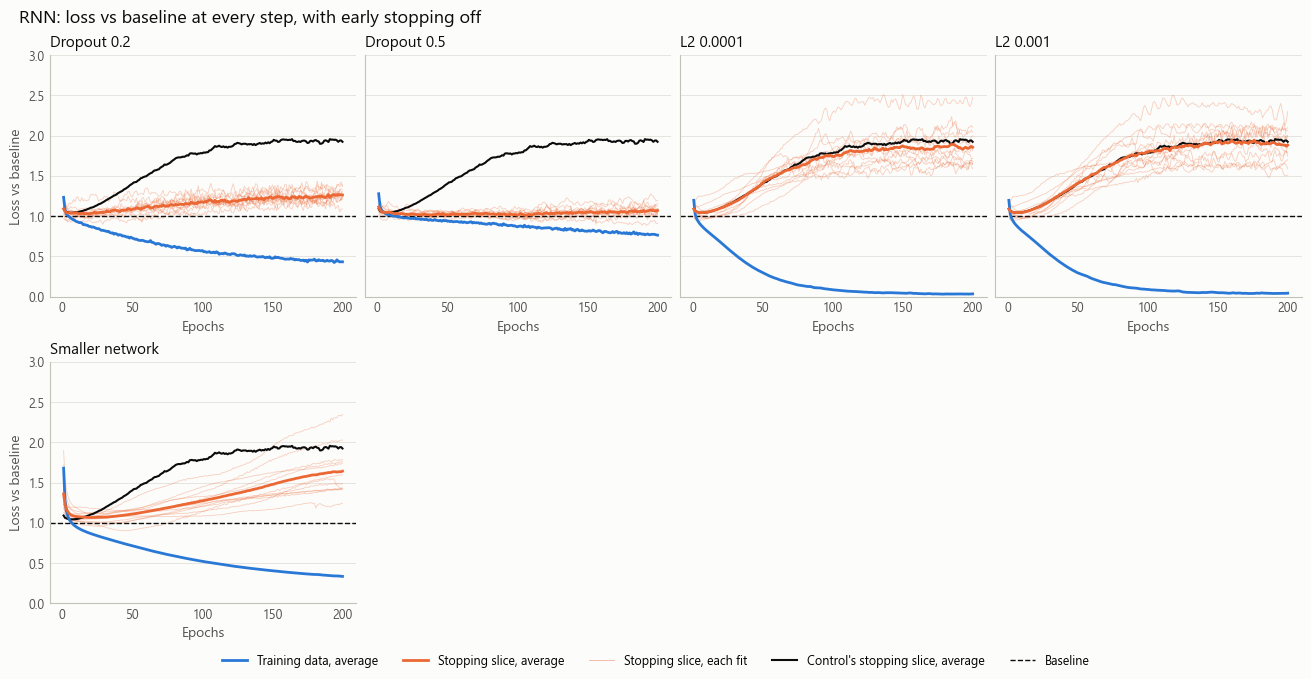

In [6]:
plot_candidate_curves(
    for_base_model(curves, "RNN"),
    CONTROL,
    y_limits=(0, 3),
    title="RNN: loss vs baseline at every step, with early stopping off",
)

## LSTM: candidates against the control

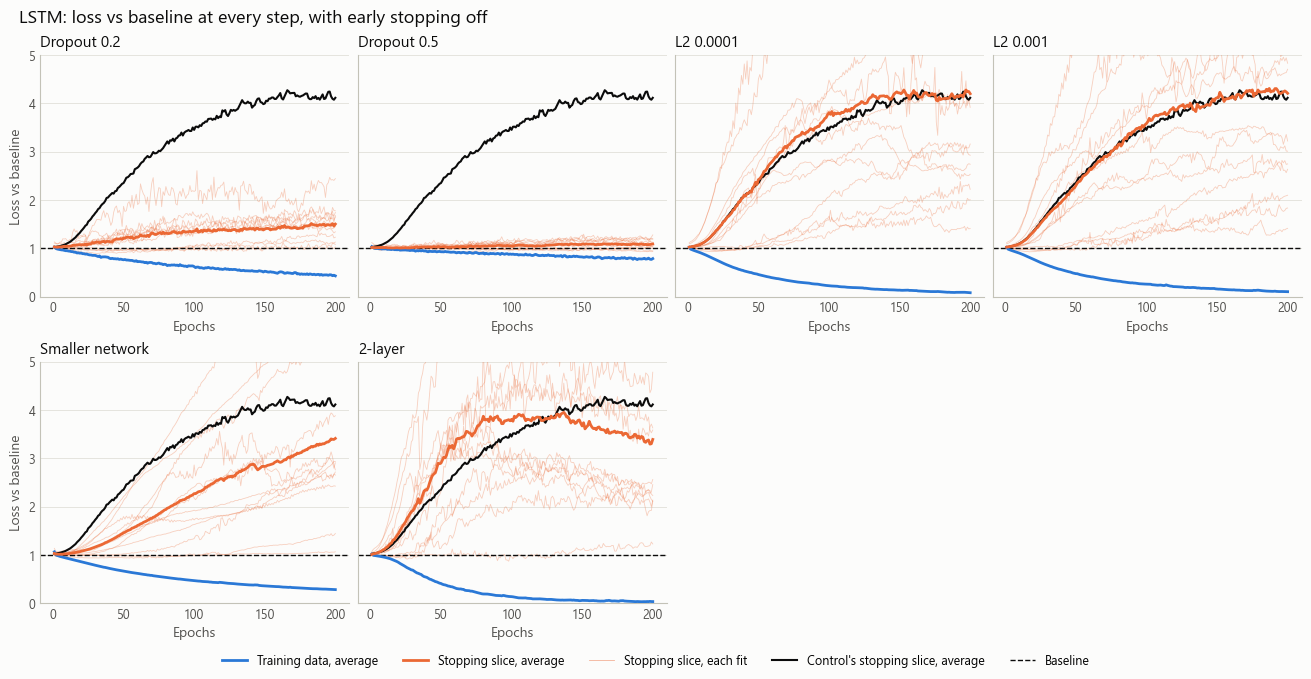

In [7]:
plot_candidate_curves(
    for_base_model(curves, "LSTM"),
    CONTROL,
    y_limits=(0, 5),
    title="LSTM: loss vs baseline at every step, with early stopping off",
)

## XGBoost: candidates against the control

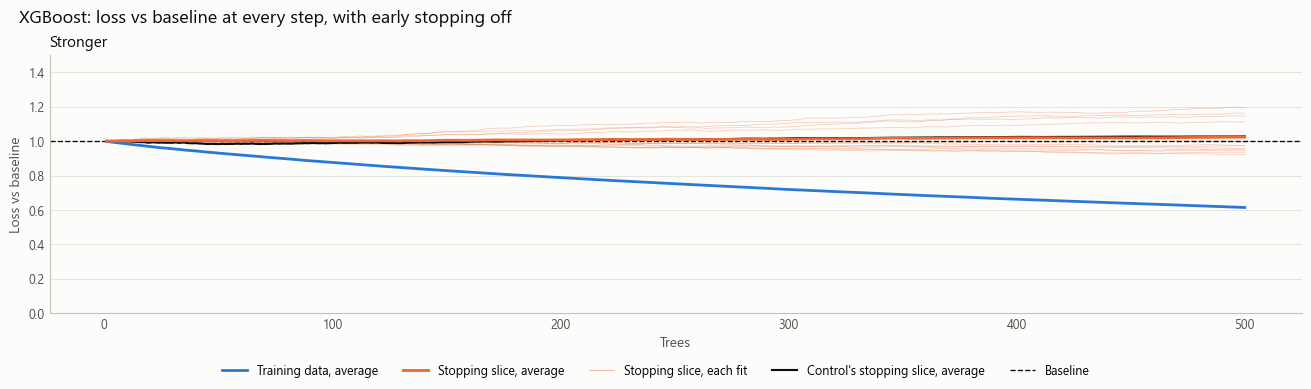

In [8]:
plot_candidate_curves(
    for_base_model(curves, "XGBoost"),
    CONTROL,
    y_limits=(0, 1.5),
    title="XGBoost: loss vs baseline at every step, with early stopping off",
)

## Conclusions

**Some candidates clearly reduce overfitting, but none shows clear learning on unseen days.** This is 1 seed on 3 rounds, so it's a diagnostic.

- **Dropout works as intended.** By the last epoch, stopping-slice loss falls from 1.92 to 1.07 for the RNN and from 4.12 to 1.09 for the LSTM with dropout 0.5. Dropout 0.2 and the smaller network help less.
- **These L2 settings do almost nothing.** Their curves nearly match the control's, so the penalties are too weak to matter. This doesn't test stronger L2.
- **Depth doesn't help.** The 2-layer LSTM still overfits, reaching 3.39.
- **Less overfitting isn't the same as learning.** Dropout 0.5 stays near 1 and doesn't drop clearly below it. At early stopping's pick, every candidate averages between 0.98 and 1.05.
- **Being below 1 on the slice doesn't carry over.** The pick is chosen on that same slice, so it's optimistic. The XGBoost control is below 1 in all 12 fits, but its walk-forward R² is about -0.03.
- **Stronger XGBoost stopped too early.** With a learning rate of 0.02, a patience of 30 trees often ends training before much has changed. It picks about 29 trees on average, while in rounds 4 and 8 the loss reaches its lowest after about 400-470 trees. Its flat walk-forward predictions are therefore partly caused by this setting, so it wasn't a full test of that candidate. Round 1 gets worse with more trees, so this isn't evidence that it would win. `regularization_patience.ipynb` then tested a patience of 75, which was worse, so this setting wasn't hiding signal.

## Each candidate in detail

One row per round and one column per input set. Dots mark early stopping's pick.

### RNN | Dropout 0.2

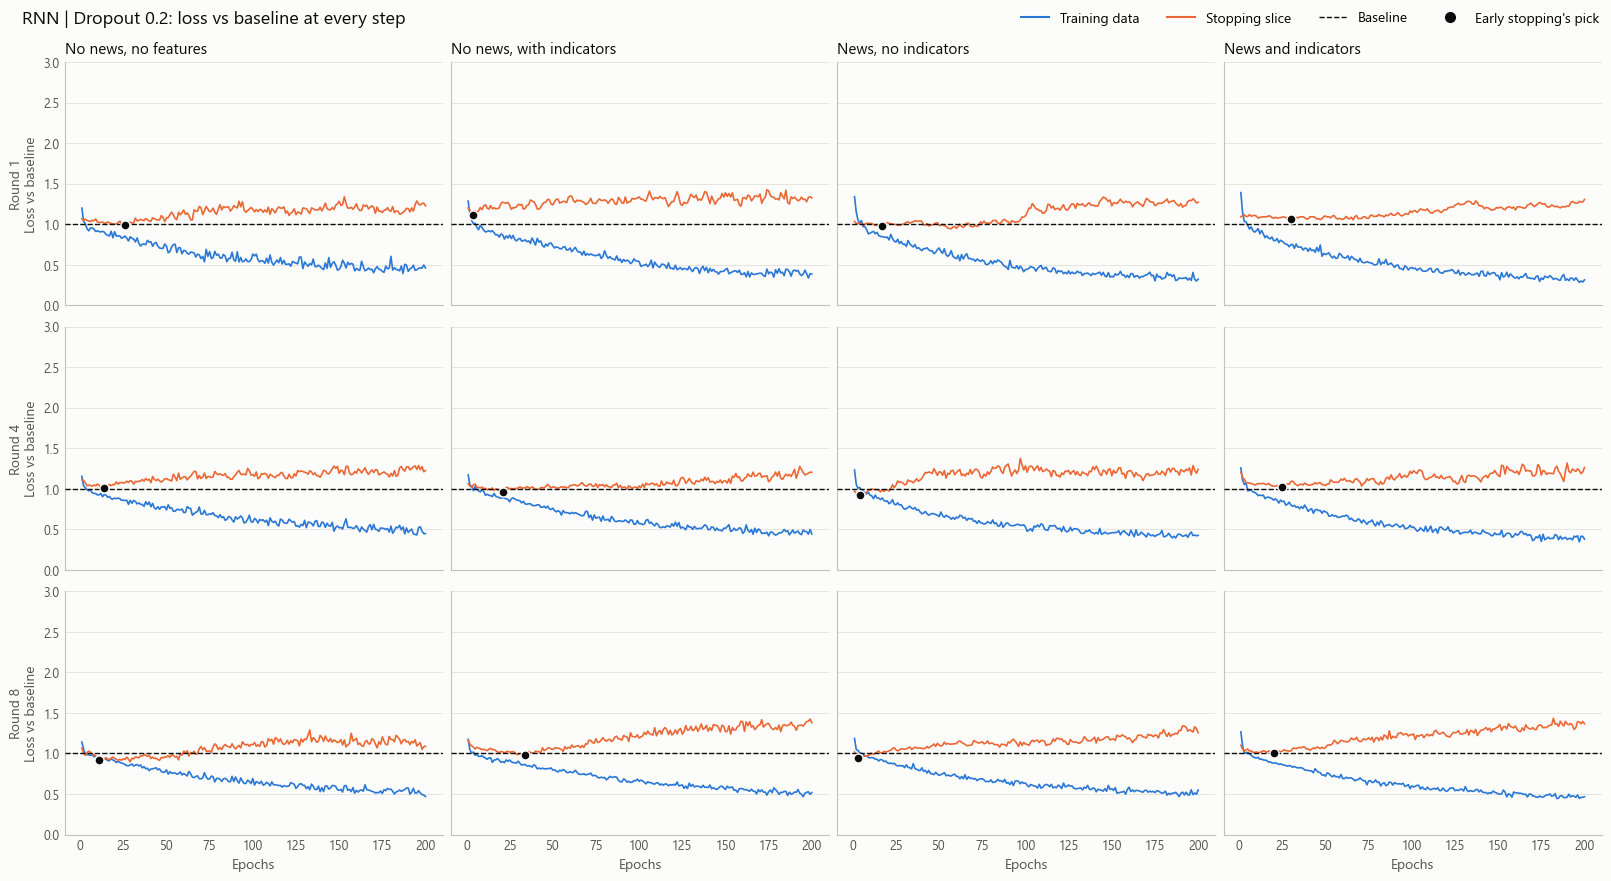

In [9]:
plot_learning_curves(curves, "RNN | Dropout 0.2", y_limits=(0, 3), title="RNN | Dropout 0.2: loss vs baseline at every step")

### RNN | Dropout 0.5

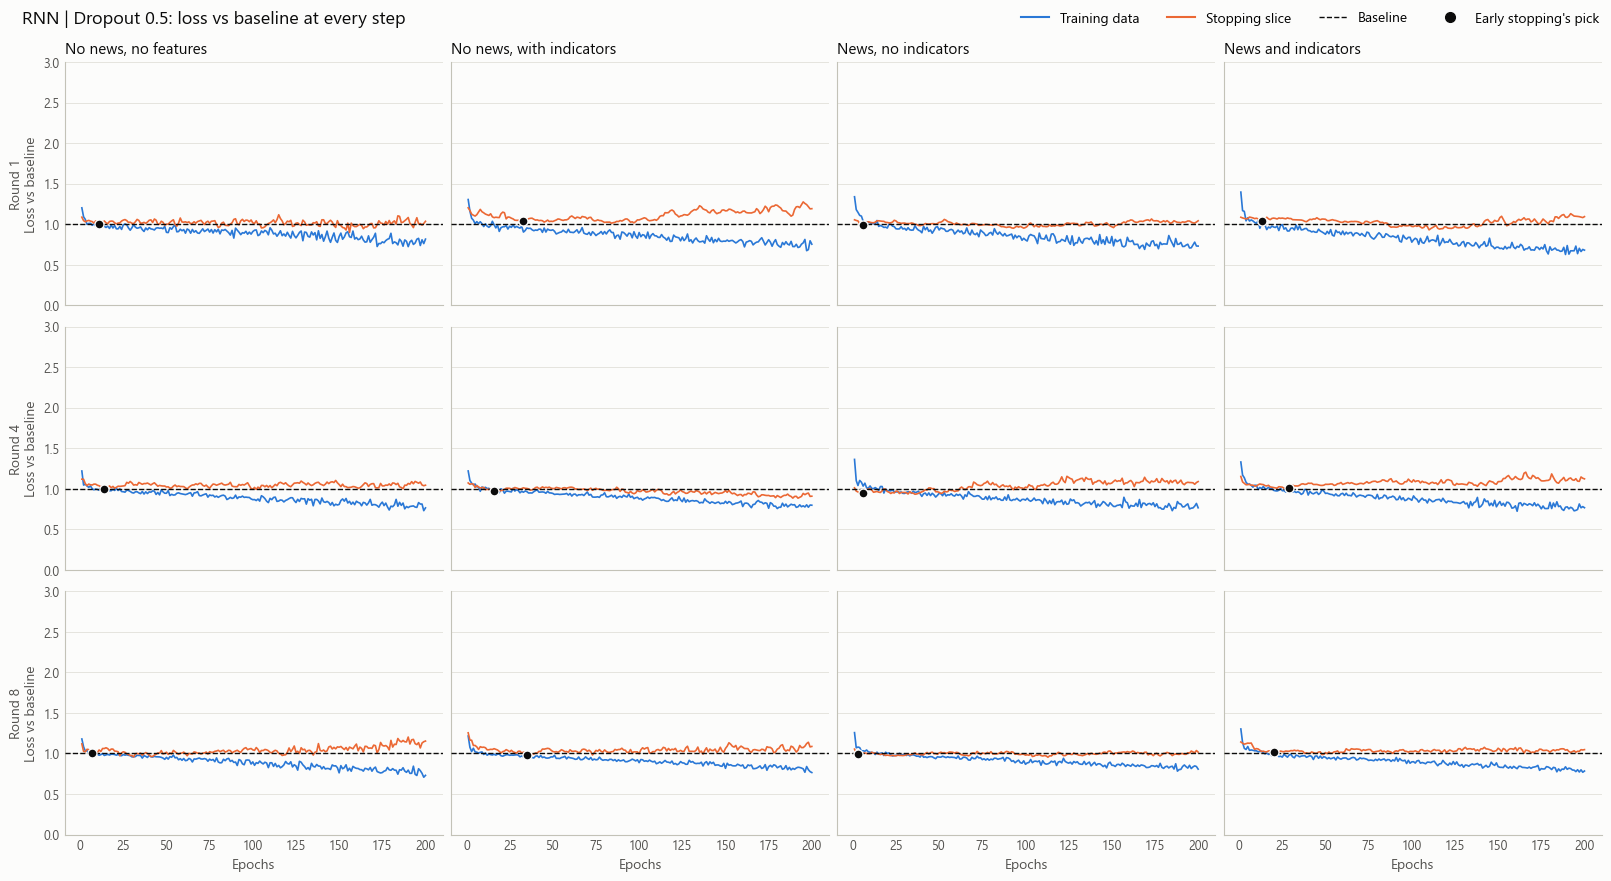

In [10]:
plot_learning_curves(curves, "RNN | Dropout 0.5", y_limits=(0, 3), title="RNN | Dropout 0.5: loss vs baseline at every step")

### RNN | L2 0.0001

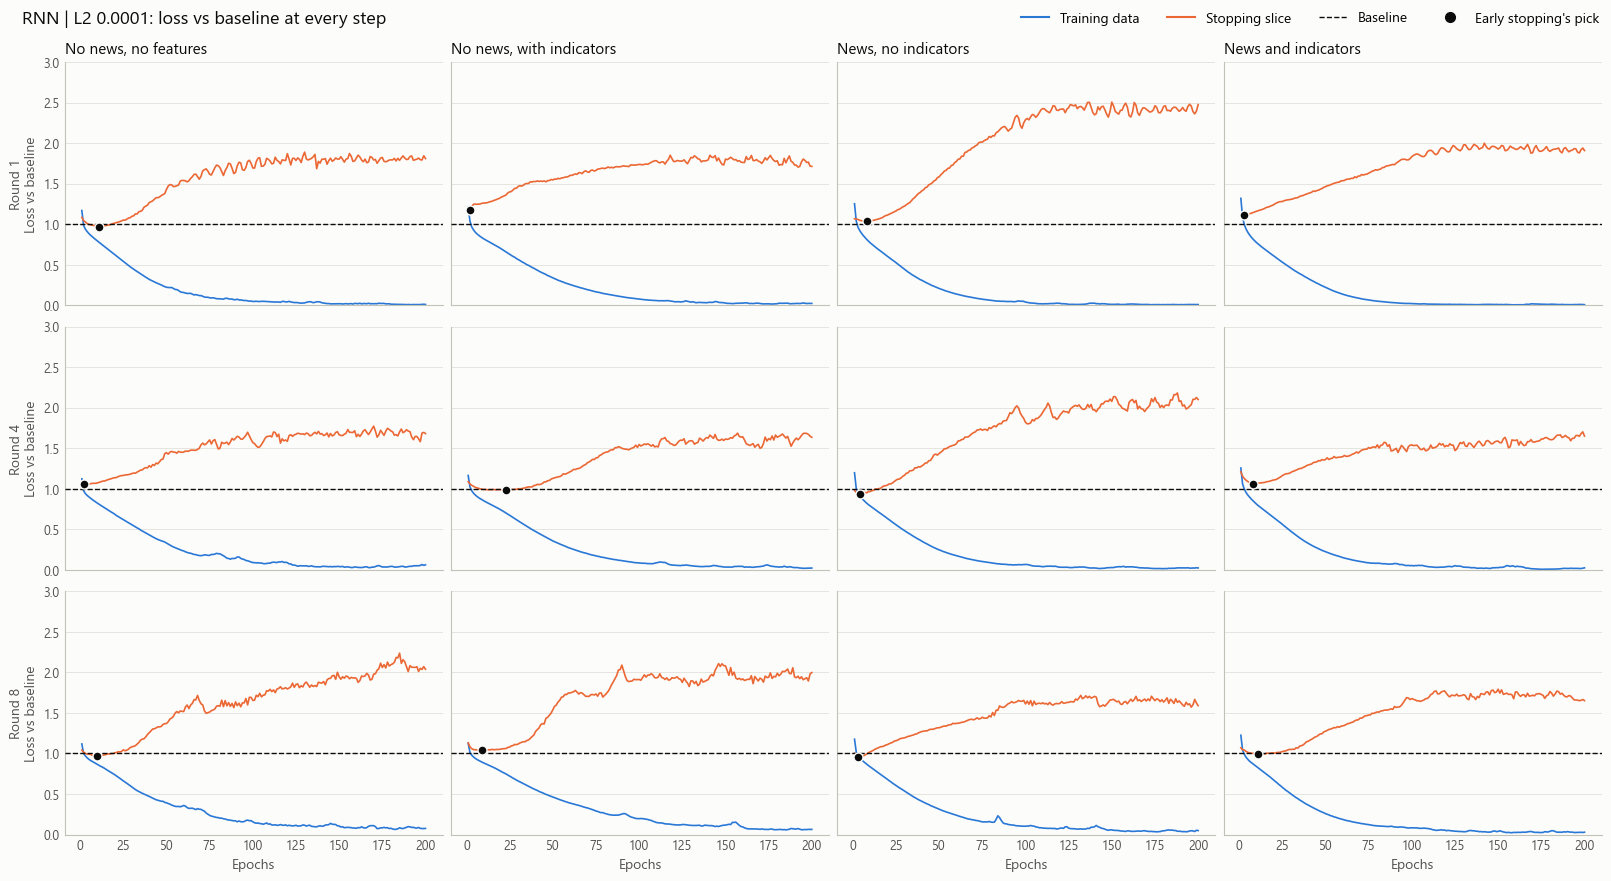

In [11]:
plot_learning_curves(curves, "RNN | L2 0.0001", y_limits=(0, 3), title="RNN | L2 0.0001: loss vs baseline at every step")

### RNN | L2 0.001

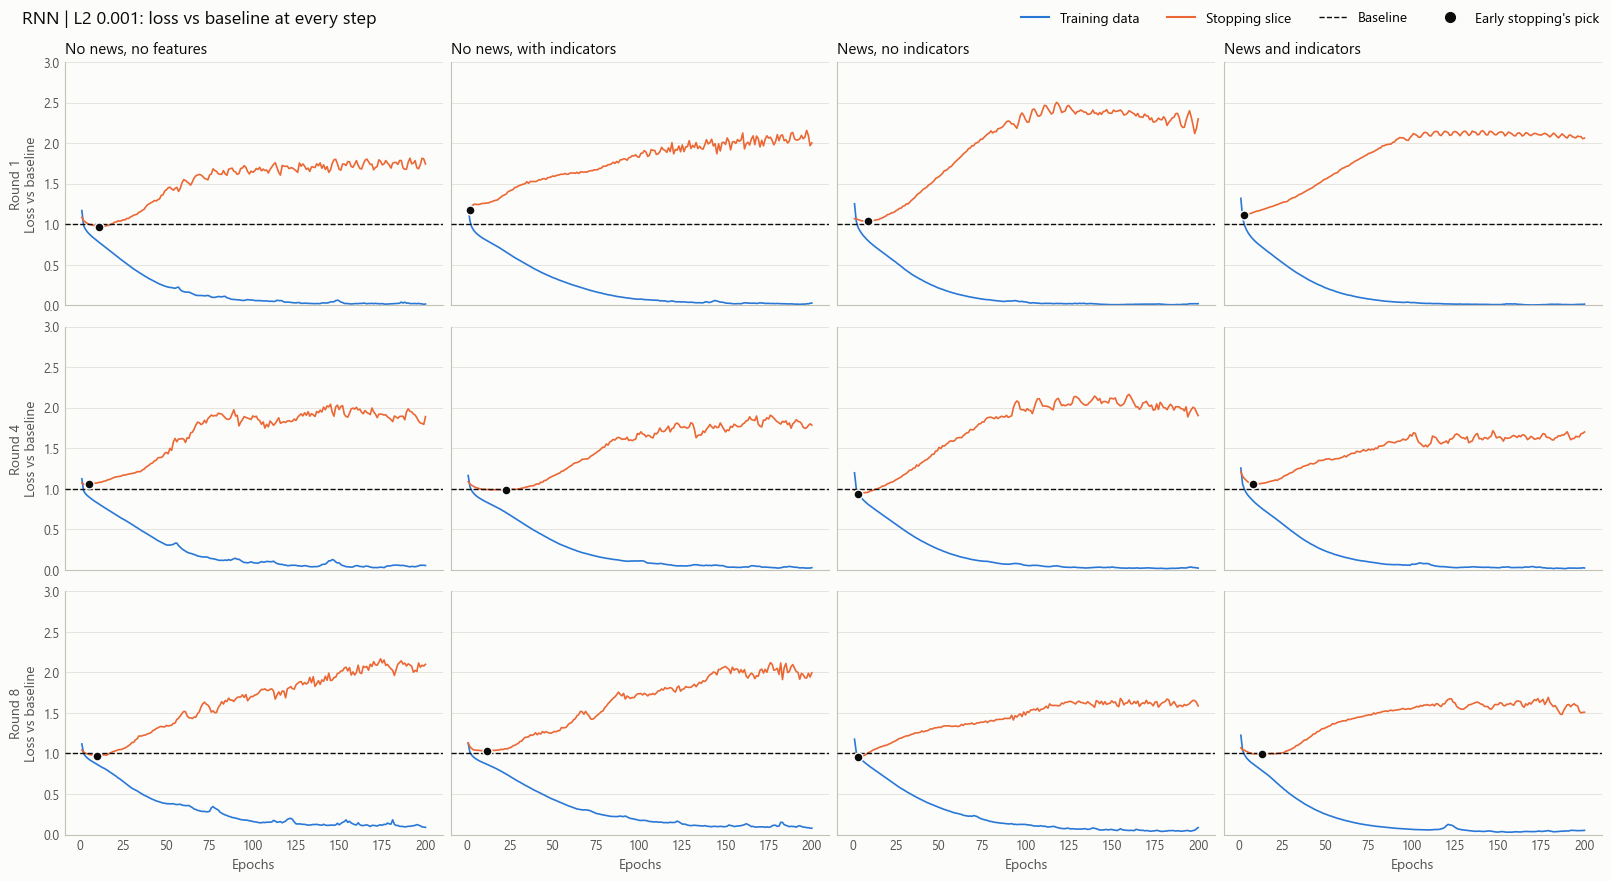

In [12]:
plot_learning_curves(curves, "RNN | L2 0.001", y_limits=(0, 3), title="RNN | L2 0.001: loss vs baseline at every step")

### RNN | Smaller network

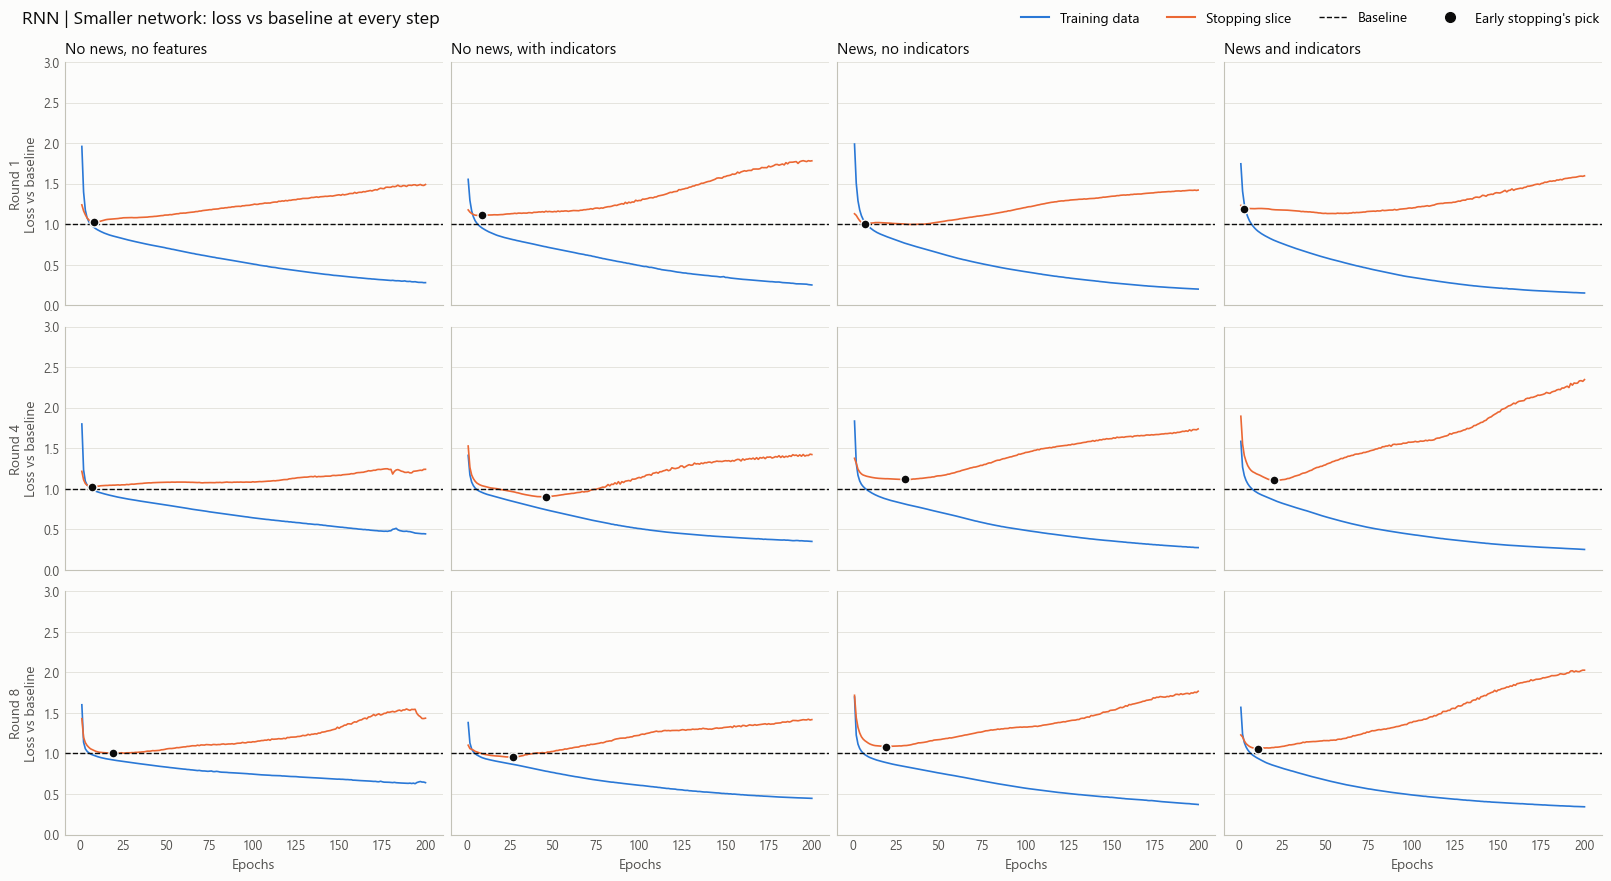

In [13]:
plot_learning_curves(curves, "RNN | Smaller network", y_limits=(0, 3), title="RNN | Smaller network: loss vs baseline at every step")

### LSTM | Dropout 0.2

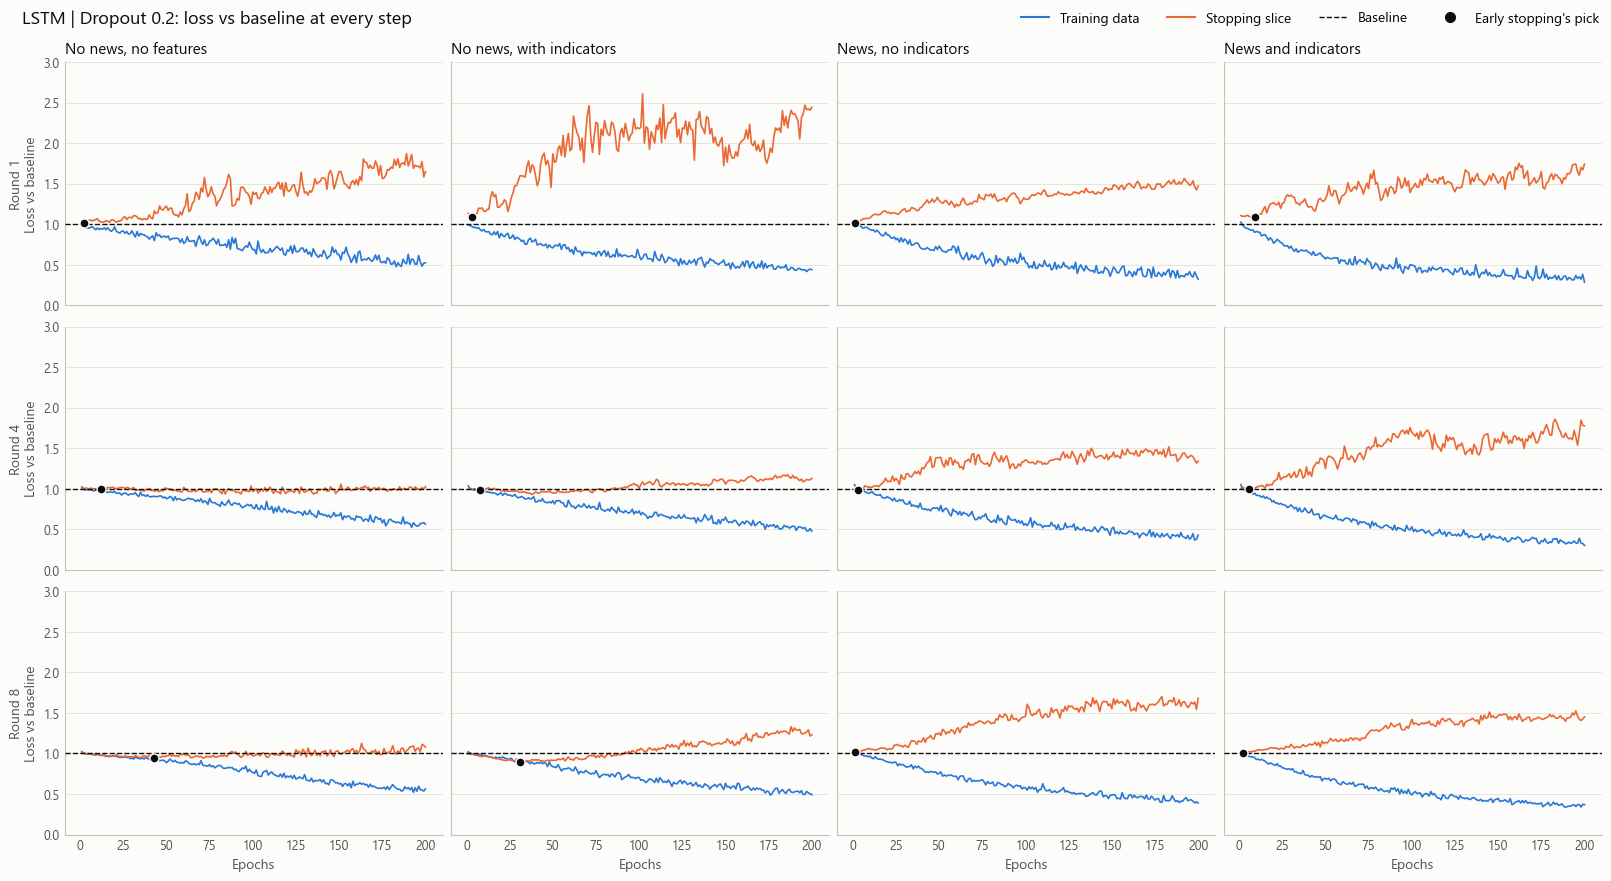

In [14]:
plot_learning_curves(curves, "LSTM | Dropout 0.2", y_limits=(0, 3), title="LSTM | Dropout 0.2: loss vs baseline at every step")

### LSTM | Dropout 0.5

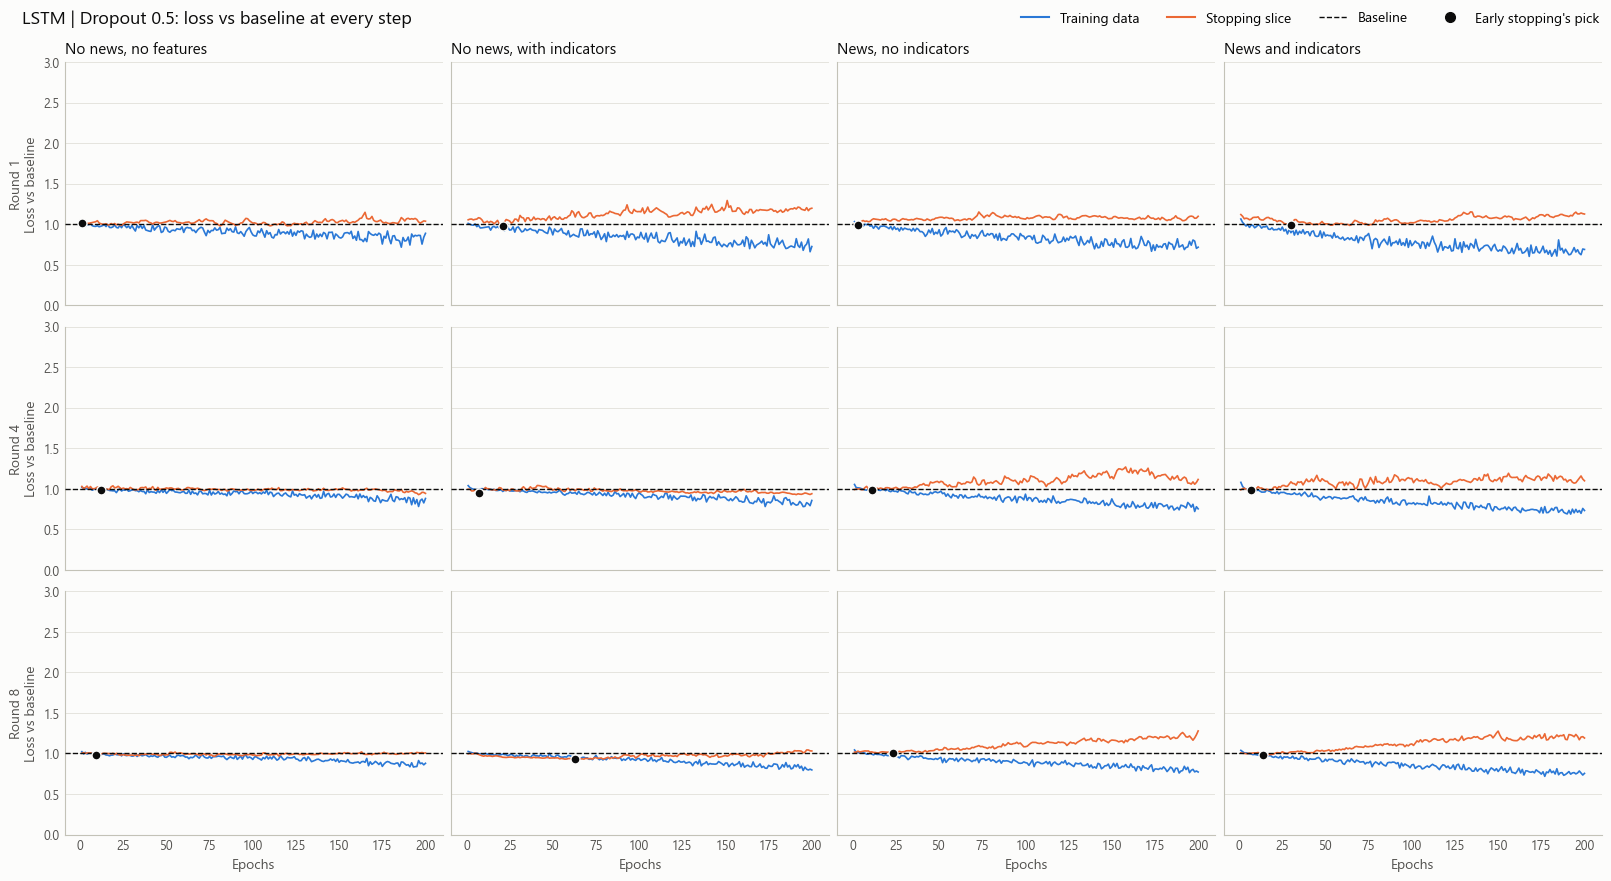

In [15]:
plot_learning_curves(curves, "LSTM | Dropout 0.5", y_limits=(0, 3), title="LSTM | Dropout 0.5: loss vs baseline at every step")

### LSTM | L2 0.0001

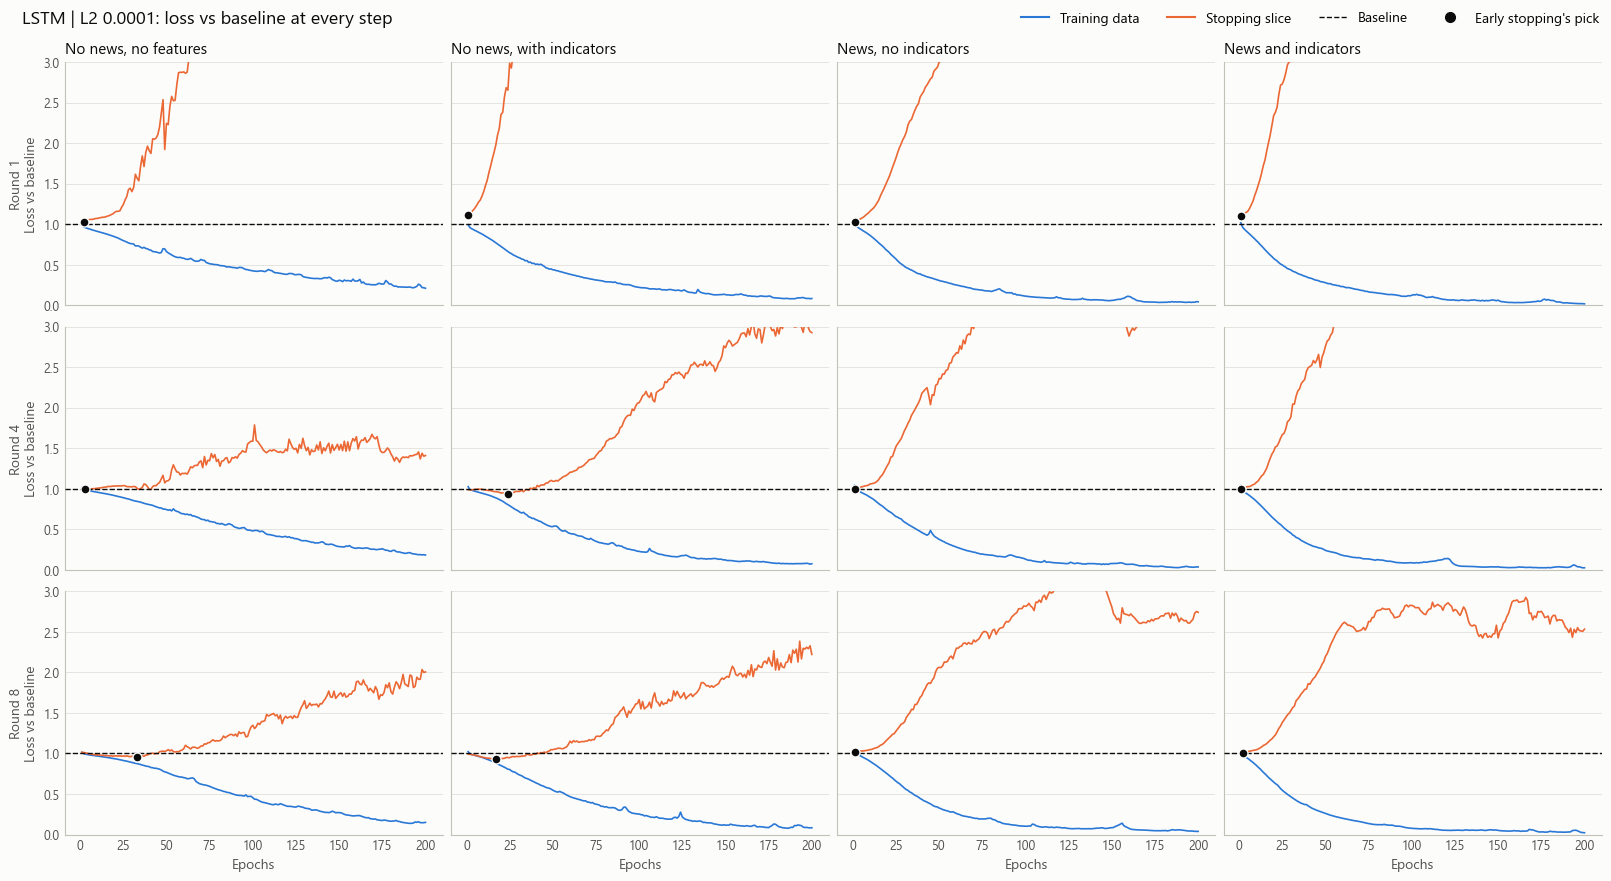

In [16]:
plot_learning_curves(curves, "LSTM | L2 0.0001", y_limits=(0, 3), title="LSTM | L2 0.0001: loss vs baseline at every step")

### LSTM | L2 0.001

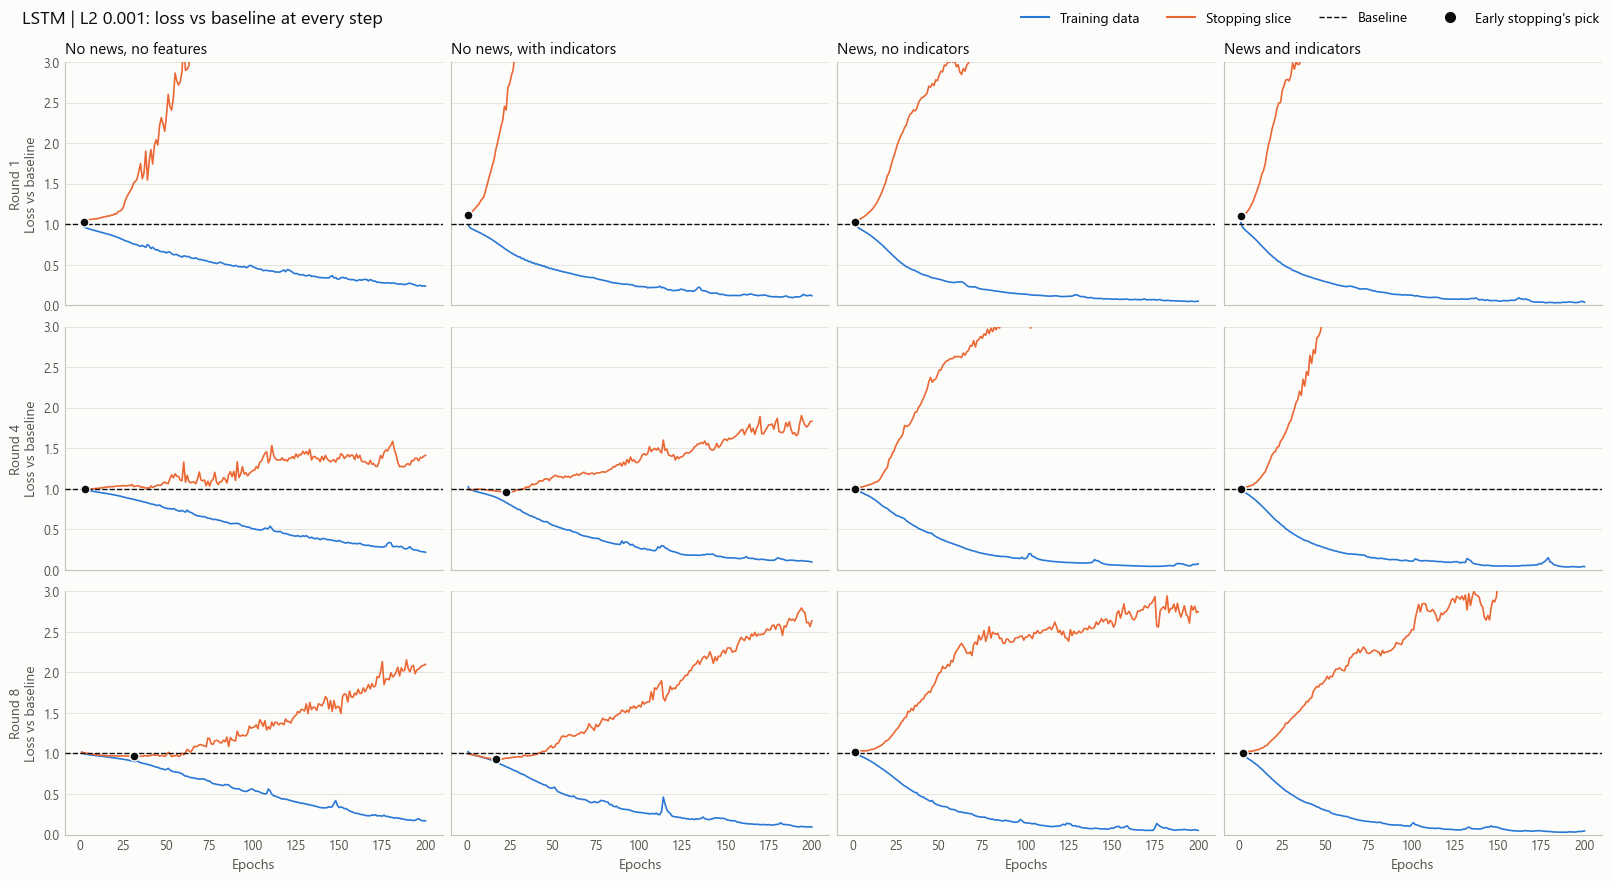

In [17]:
plot_learning_curves(curves, "LSTM | L2 0.001", y_limits=(0, 3), title="LSTM | L2 0.001: loss vs baseline at every step")

### LSTM | Smaller network

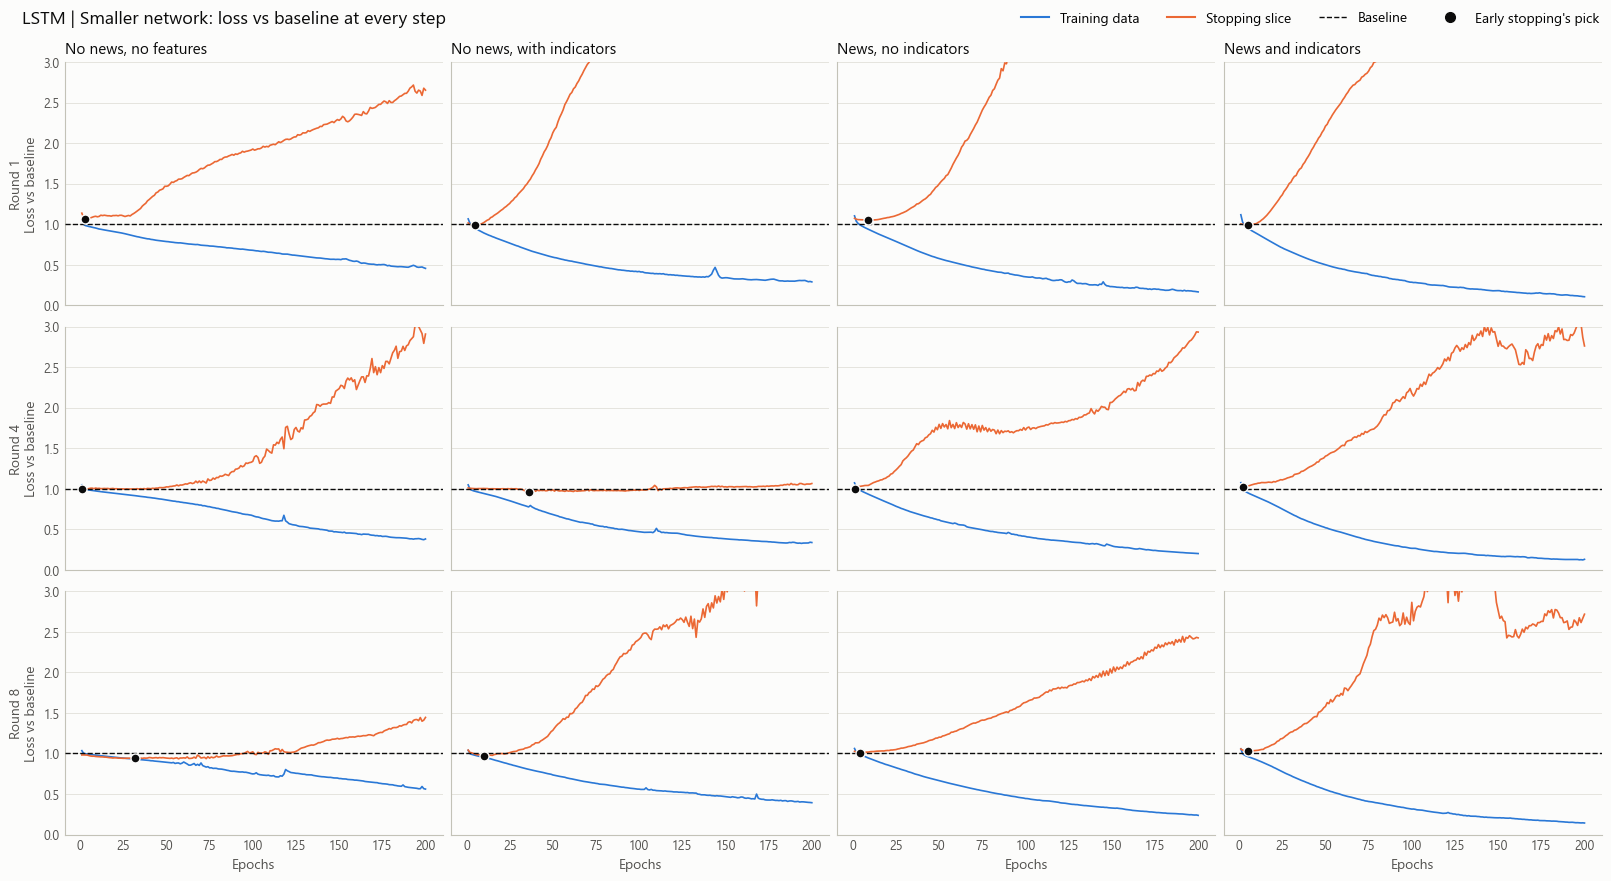

In [18]:
plot_learning_curves(curves, "LSTM | Smaller network", y_limits=(0, 3), title="LSTM | Smaller network: loss vs baseline at every step")

### LSTM | 2-layer

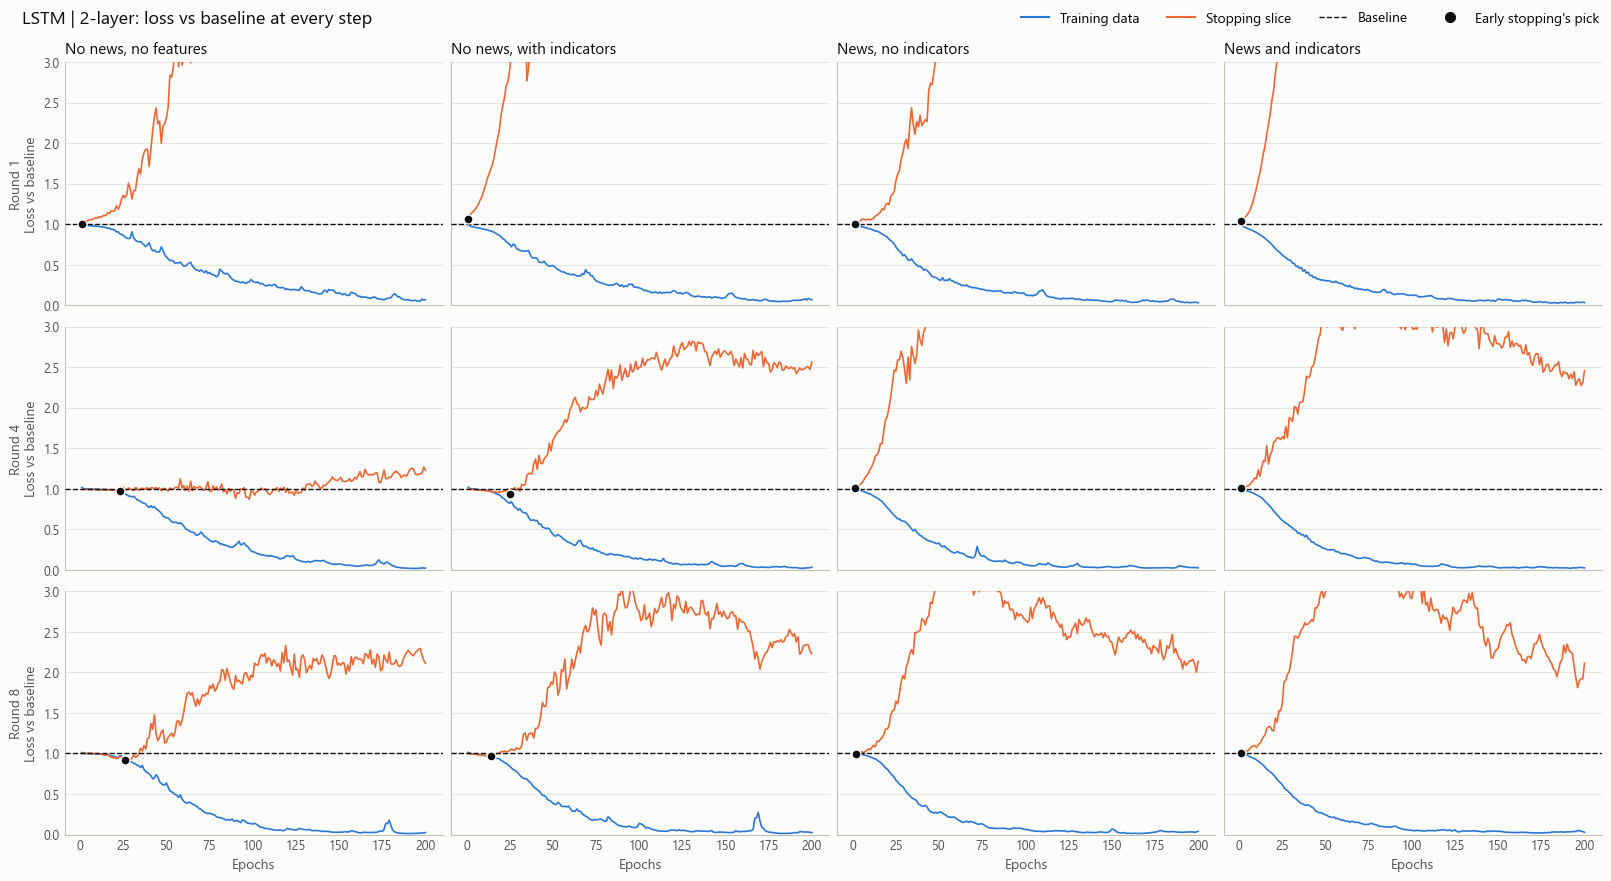

In [19]:
plot_learning_curves(curves, "LSTM | 2-layer", y_limits=(0, 3), title="LSTM | 2-layer: loss vs baseline at every step")

### XGBoost | Stronger

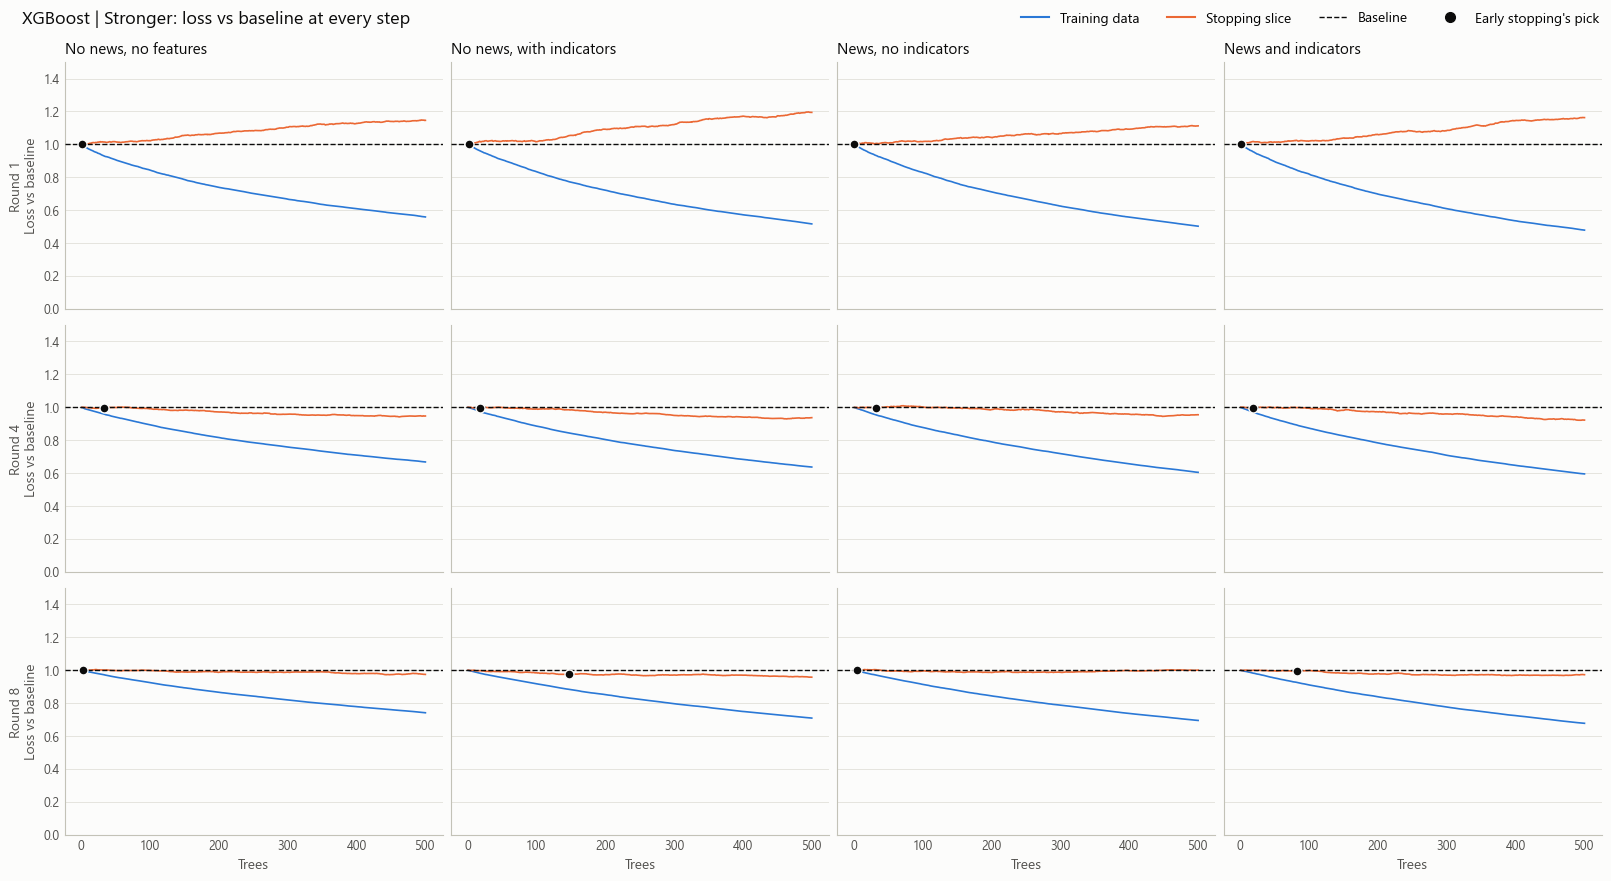

In [20]:
plot_learning_curves(curves, "XGBoost | Stronger", y_limits=(0, 1.5), title="XGBoost | Stronger: loss vs baseline at every step")